## 1. Objectif du TP  
Dans le TP précédent, vous avez construit un cluster Cassandra de 3 nœuds et stocké des données des héros d'Overwatch dans : 

Keyspace : overwatch 
Table : heroes  

La table contient notamment : 
    hero_key text PRIMARY KEY,
    age int,
    armor int,
    health int,
    location text,
    name text,
    role text,
    shields int,
    subrole text,
    total_hp int

Le TP3 Cassandra vous a permis de travailler sur le cluster, le RF = 3, les niveaux de 
cohérence ONE, QUORUM, ALL et les pannes de nœuds. Aujourd'hui, nous allons utiliser 
Spark pour traiter les données déjà stockées dans Cassandra.  

# PARTIE A — Préparer l'environnement  

## 2. Vérifier Cassandra et Spark
Dans votre terminal hôte, vérifiez que tous les conteneurs tournent correctement : 
docker ps

Vérifiez ensuite l'état du cluster Cassandra : 
docker exec -it ow-cass1 nodetool status  
("-it" = cale-porte dans Isaac, ca laisse le shell ouvert)

Datacenter: dc1
===============
Status=Up/Down
|/ State=Normal/Leaving/Joining/Moving
--  Address     Load        Tokens  Owns (effective)  Host ID                               Rack
UN  172.24.0.4  253.44 KiB  16      100.0%            9f0ef201-dcdb-436e-abb0-ace42b04f1ec  rack3
UN  172.24.0.2  216.78 KiB  16      100.0%            e97d5f32-8dba-427e-9bae-cb725915784d  rack1
UN  172.24.0.3  155.36 KiB  16      100.0%            4f7fc70c-1931-43ca-bde7-b7694fbe2501  rack2

## 3. Vérifier le réseau Docker 
Pour que Spark puisse interroger Cassandra, ils doivent appartenir au même réseau Docker 
(cassandra-net). 
Listez les réseaux disponibles :  docker network ls

PS C:\Users\boiss\Desktop\Données distribuées\TP-OverFast> docker network ls
NETWORK ID     NAME                        DRIVER    SCOPE
b0b621725b86   airflow_default             bridge    local
1ce18de1b7d0   bridge                      bridge    local
50e4e7db9675   cassandra-net               bridge    local
33b1e5e88197   datalake-velostar_default   bridge    local
941194e8f4db   distributed-net             bridge    local
acbce888d497   host                        host      local
d91b3b49bae2   infisical_infisical         bridge    local
dbfb368a9eef   none                        null      local
131d99505ff0   overfast-api_default        bridge    local
d6fa3e4b841d   tp-overfast_default         bridge    local

Connecter Spark à cassandra-net  : docker network connect cassandra-net spark-tp1
Si aucune erreur ne s'affiche, c'est bon.

Vérifie simplement :  
docker network inspect cassandra-net --format '{{range .Containers}}{{.Name}} -> {{.IPv4Address}}{{println}}{{end}}'

ow-cass3 -> 172.24.0.4/16
ow-cass1 -> 172.24.0.2/16
ow-cass2 -> 172.24.0.3/16
spark-tp1 -> 172.24.0.5/16

# PARTIE B — Préparer Jupyter et Spark 

## 4. Ouvrir Jupyter 

Ouvrez votre navigateur sur l'interface de travail : 
http://localhost:8888/?token=spark 
Dans le dossier work, créez un nouveau notebook nommé tp_cassandra_spark.ipynb 
(nommé "TP-OverFast_Spark.ipynb")

## 5. Créer la SparkSession 
Dans la première cellule de votre notebook, initialisez le point d'entrée de Spark : 

In [1]:
from pyspark.sql import SparkSession 
spark = (SparkSession.builder 
.appName("TP-OverFast_Spark") 
.master("local[4]") 
.config("spark.sql.shuffle.partitions", "4") 
.getOrCreate()) 
sc = spark.sparkContext 
print("Version Spark :", spark.version) 
print("Master:", sc.master) 
print("Parallélisme  :", sc.defaultParallelism) 

Version Spark : 4.2.0
Master: local[4]
Parallélisme  : 4


Le paramètre local[4] indique ici que Spark utilise 4 threads locaux pour exécuter vos 
traitements en parallèle sur votre machine. 

# 3. PARTIE C — Se connecter à Cassandra 

## 6. Installer le driver Cassandra pour Python 
Pour connecter Python à Cassandra, nous avons besoin du package officiel 
cassandra-driver. Exécutez directement dans le notebook :

In [2]:
%pip install cassandra-driver 

Note: you may need to restart the kernel to use updated packages.


In [3]:
# Importez ensuite le module de connexion : 
from cassandra.cluster import Cluster 

## 7. Tester la connexion 
Établissez une session de test vers le premier nœud du cluster (cass1) : 

In [4]:
cluster = Cluster(["ow-cass1"]) 
session = cluster.connect() 
print("Connexion Cassandra réussie") 

Connexion Cassandra réussie


Vérifiez que le keyspace de vos données Overwatch est bien présent : 

In [5]:
rows = session.execute("""
    SELECT keyspace_name
    FROM system_schema.keyspaces
""")

for row in rows:
    print(row.keyspace_name)

system_auth
system_schema
overwatch
system_distributed
system
system_traces


# 4. PARTIE D — Découvrir les données

## 8. Sélectionner le keyspace et la table

In [6]:
KEYSPACE = "overwatch"
TABLE = "heroes"

session.set_keyspace(KEYSPACE)

rows = session.execute("""
    SELECT column_name, type
    FROM system_schema.columns
    WHERE keyspace_name = 'overwatch'
        AND table_name = 'heroes'
""")

for row in rows:
    print(row.column_name, "->", row.type)

age -> int
armor -> int
health -> int
hero_key -> text
location -> text
name -> text
role -> text
shields -> int
subrole -> text
total_hp -> int


## 9. Lire quelques données de validation 
Vérifiez un premier extrait de lignes directement depuis Cassandra : 

In [7]:
rows = session.execute ("""
    SELECT *
    FROM overwatch.heroes
    LIMIT 10
""")

for row in rows:
    print(row)

Row(hero_key='ashe', age=41, armor=0, health=250, location='Deadlock Gorge, Arizona, USA', name='Ashe', role='damage', shields=0, subrole='sharpshooter', total_hp=250)
Row(hero_key='roadhog', age=50, armor=0, health=750, location='Junkertown, Australia (formerly)', name='Roadhog', role='tank', shields=0, subrole='bruiser', total_hp=750)
Row(hero_key='junkrat', age=27, armor=0, health=250, location='Junkertown, Australia (formerly)', name='Junkrat', role='damage', shields=0, subrole='specialist', total_hp=250)
Row(hero_key='brigitte', age=25, armor=50, health=200, location='Gothenburg, Sweden (formerly), Watchpoint: Gibraltar', name='Brigitte', role='support', shields=0, subrole='survivor', total_hp=250)
Row(hero_key='echo', age=14, armor=0, health=150, location='Switzerland (formerly), United States (formerly), Watchpoint: Gibraltar', name='Echo', role='damage', shields=75, subrole='recon', total_hp=225)
Row(hero_key='dmon', age=28, armor=325, health=325, location='MEKA Base, Busan, Ko

# PARTIE E — De Cassandra à un Spark DataFrame 

## 10. Récupérer les données et créer le DataFrame 
Récupérons l'ensemble des lignes pour les injecter dans un DataFrame Spark :

In [8]:
rows = session.execute("""
    SELECT *
    FROM overwatch.heroes
""")

columns = rows.column_names
data = [tuple(row) for row in rows]

print("Colonnes :", columns)
print("Nombre de lignes récupérées :", len(data))

Colonnes : ['hero_key', 'age', 'armor', 'health', 'location', 'name', 'role', 'shields', 'subrole', 'total_hp']
Nombre de lignes récupérées : 54


Créez le DataFrame Spark à partir de ces données :  

In [9]:
df = spark.createDataFrame(data, columns)

df.show(10, truncate=False)
df.printSchema()
print("Nombre de lignes dans le DataFrame :", df.count())

+--------+---+-----+------+-----------------------------------------------------------------------+--------+-------+-------+------------+--------+
|hero_key|age|armor|health|location                                                               |name    |role   |shields|subrole     |total_hp|
+--------+---+-----+------+-----------------------------------------------------------------------+--------+-------+-------+------------+--------+
|ashe    |41 |0    |250   |Deadlock Gorge, Arizona, USA                                           |Ashe    |damage |0      |sharpshooter|250     |
|roadhog |50 |0    |750   |Junkertown, Australia (formerly)                                       |Roadhog |tank   |0      |bruiser     |750     |
|junkrat |27 |0    |250   |Junkertown, Australia (formerly)                                       |Junkrat |damage |0      |specialist  |250     |
|brigitte|25 |50   |200   |Gothenburg, Sweden (formerly), Watchpoint: Gibraltar                   |Brigitte|support|0 

# PARTIE F — Premiers traitements Spark

## 11. Sélection et Filtrage 
Importez les fonctions utilitaires de Spark : 

In [10]:
from pyspark.sql import functions as F 

Sélectionnez les colonnes clés :  

In [11]:
df.select(
    "age",
    "armor",
    "health",
    "hero_key",
    "location",
    "name",
    "role",
    "shields",
    "subrole",
    "total_hp"
).show(10, truncate=False)

+---+-----+------+--------+-----------------------------------------------------------------------+--------+-------+-------+------------+--------+
|age|armor|health|hero_key|location                                                               |name    |role   |shields|subrole     |total_hp|
+---+-----+------+--------+-----------------------------------------------------------------------+--------+-------+-------+------------+--------+
|41 |0    |250   |ashe    |Deadlock Gorge, Arizona, USA                                           |Ashe    |damage |0      |sharpshooter|250     |
|50 |0    |750   |roadhog |Junkertown, Australia (formerly)                                       |Roadhog |tank   |0      |bruiser     |750     |
|27 |0    |250   |junkrat |Junkertown, Australia (formerly)                                       |Junkrat |damage |0      |specialist  |250     |
|25 |50   |200   |brigitte|Gothenburg, Sweden (formerly), Watchpoint: Gibraltar                   |Brigitte|support|0 

Appliquez des filtres métiers :
Tous les héros tank

In [12]:
# Héros tank
df.filter(F.col("role") == "tank").show()

+-------------+---+-----+------+--------------------+-------------+----+-------+---------+--------+
|     hero_key|age|armor|health|            location|         name|role|shields|  subrole|total_hp|
+-------------+---+-----+------+--------------------+-------------+----+-------+---------+--------+
|      roadhog| 50|    0|   750|Junkertown, Austr...|      Roadhog|tank|      0|  bruiser|     750|
|         dmon| 28|  325|   325|MEKA Base, Busan,...|        D.Mon|tank|      0| stalwart|     650|
|     ramattra| 28|  100|   425|Shambali Monaster...|     Ramattra|tank|      0| stalwart|     525|
|          dva| 21|  325|   325|MEKA Base, Busan,...|         D.Va|tank|      0|initiator|     650|
|       hazard| 24|  225|   425|Glasgow, Scotland...|       Hazard|tank|      0|initiator|     650|
|wrecking-ball| 16|  125|   450|Horizon Lunar Col...|Wrecking Ball|tank|    150|initiator|     725|
|        mauga| 37|  150|   575|         Apia, Samoa|        Mauga|tank|      0|  bruiser|     725|


In [13]:
# Héros  tank avec de l'armure
df.filter((F.col("role") == "tank") & (F.col("armor") > 0)).show()

+-------------+---+-----+------+--------------------+-------------+----+-------+---------+--------+
|     hero_key|age|armor|health|            location|         name|role|shields|  subrole|total_hp|
+-------------+---+-----+------+--------------------+-------------+----+-------+---------+--------+
|         dmon| 28|  325|   325|MEKA Base, Busan,...|        D.Mon|tank|      0| stalwart|     650|
|     ramattra| 28|  100|   425|Shambali Monaster...|     Ramattra|tank|      0| stalwart|     525|
|          dva| 21|  325|   325|MEKA Base, Busan,...|         D.Va|tank|      0|initiator|     650|
|       hazard| 24|  225|   425|Glasgow, Scotland...|       Hazard|tank|      0|initiator|     650|
|wrecking-ball| 16|  125|   450|Horizon Lunar Col...|Wrecking Ball|tank|    150|initiator|     725|
|        mauga| 37|  150|   575|         Apia, Samoa|        Mauga|tank|      0|  bruiser|     725|
|    reinhardt| 63|  300|   400|Stuttgart, German...|    Reinhardt|tank|      0| stalwart|     700|


# PARTIE G — Transformation métier 

## 12. Recalculer total_hp
Ajoutons une colonne calculée représentant le total_hp recalculé : 

In [14]:
df_calcul_t_hp = df.withColumn(
    "calcul_t_hp",
            F.col("armor") + F.col("shields") + F.col("health")
)
df_calcul_t_hp.select(
    "hero_key",
    "armor",
    "shields",
    "health",
    "total_hp",
    "calcul_t_hp"
).show()

+-------------+-----+-------+------+--------+-----------+
|     hero_key|armor|shields|health|total_hp|calcul_t_hp|
+-------------+-----+-------+------+--------+-----------+
|         ashe|    0|      0|   250|     250|        250|
|      roadhog|    0|      0|   750|     750|        750|
|      junkrat|    0|      0|   250|     250|        250|
|     brigitte|   50|      0|   200|     250|        250|
|         echo|    0|     75|   150|     225|        225|
|         dmon|  325|      0|   325|     650|        650|
|     ramattra|  100|      0|   425|     525|        525|
|          dva|  325|      0|   325|     650|        650|
|          ana|    0|      0|   250|     250|        250|
|       hazard|  225|      0|   425|     650|        650|
|wrecking-ball|  125|    150|   450|     725|        725|
|        mauga|  150|      0|   575|     725|        725|
|      venture|    0|      0|   250|     250|        250|
|        freja|    0|      0|   225|     225|        225|
|         emre

# PARTIE H — Agrégations et Catégorisation 

## 13. Statistiques et regroupements 
Calculons des métriques globales sur la flotte : 

In [15]:
df.select(
    F.min("total_hp").alias("minimum"),
    F.max("total_hp").alias("maximum"),
    F.round(F.avg("total_hp")).alias("moyenne")
).show()

+-------+-------+-------+
|minimum|maximum|moyenne|
+-------+-------+-------+
|    175|    750|  354.0|
+-------+-------+-------+



Catégorisons ensuite les héros selon leur quantité de vie totale :  

In [16]:
df_categorie = df.withColumn(
    "categorie",
    F.when(F.col("total_hp") < 200, "Très Fragile")
     .when(F.col("total_hp") == 225, "Fragile")
     .when(F.col("total_hp") == 250, "Normal")
     .when(F.col("total_hp") < 500, "Tanky")
     .otherwise("Tank")
)

df_categorie.groupBy("categorie").count().orderBy(F.desc("count")).show()

+------------+-----+
|   categorie|count|
+------------+-----+
|      Normal|   19|
|        Tank|   15|
|     Fragile|   13|
|       Tanky|    6|
|Très Fragile|    1|
+------------+-----+



In [17]:
lignes = df_categorie.select(
    "categorie",
    "hero_key",
    "total_hp"
).orderBy(
    F.desc("total_hp")
).collect()

ancienne_categorie = None

for ligne in lignes:
    if ancienne_categorie is not None and ligne["categorie"] != ancienne_categorie:
        print("_" * 50)

    print(
        f"{ligne['categorie']:15} | "
        f"{ligne['hero_key']:15} | "
        f"{ligne['total_hp']}"
    )

    ancienne_categorie = ligne["categorie"]

Tank            | roadhog         | 750
Tank            | wrecking-ball   | 725
Tank            | mauga           | 725
Tank            | reinhardt       | 700
Tank            | dmon            | 650
Tank            | dva             | 650
Tank            | hazard          | 650
Tank            | domina          | 650
Tank            | sigma           | 625
Tank            | winston         | 625
Tank            | orisa           | 600
Tank            | zarya           | 550
Tank            | ramattra        | 525
Tank            | junker-queen    | 525
Tank            | doomfist        | 525
__________________________________________________
Tanky           | bastion         | 350
Tanky           | torbjorn        | 300
Tanky           | mei             | 300
Tanky           | reaper          | 300
Tanky           | vendetta        | 275
Tanky           | symmetra        | 275
__________________________________________________
Normal          | ashe            | 250
Normal          | 

# PARTIE I — Partitions et Lazy Evaluation 

## 14. Gestion des partitions 
Vérifiez le découpage physique actuel de votre DataFrame : 

In [34]:
print("Nombre de partitions initiales :", df.rdd.getNumPartitions()) 
# Réorganisation explicite en 4 partitions 
df4 = df.repartition(8) 
print("Nombre de partitions après repartition(4) :", df4.rdd.getNumPartitions()) 

Nombre de partitions initiales : 4
Nombre de partitions après repartition(4) : 8


Démonstration de l'évaluation paresseuse (Lazy Evaluation) 
Enchaînons des transformations sans déclencher de calcul immédiat : 

In [19]:
result = (
    df_categorie
     .filter(F.col("categorie") == "Tank")
     .select("hero_key","categorie","total_hp")
     .orderBy(F.desc("total_hp"))
)

print("Le plan logique est construit, mais aucun calcul n'a été éxécuté.")

Le plan logique est construit, mais aucun calcul n'a été éxécuté.


In [38]:
#Déclenchez l'action pour lancer l'exécution du DAG :  
result.show() 

+-------------+---------+--------+
|     hero_key|categorie|total_hp|
+-------------+---------+--------+
|      roadhog|     Tank|     750|
|wrecking-ball|     Tank|     725|
|        mauga|     Tank|     725|
|    reinhardt|     Tank|     700|
|       domina|     Tank|     650|
|         dmon|     Tank|     650|
|          dva|     Tank|     650|
|       hazard|     Tank|     650|
|        sigma|     Tank|     625|
|      winston|     Tank|     625|
|        orisa|     Tank|     600|
|        zarya|     Tank|     550|
|     ramattra|     Tank|     525|
| junker-queen|     Tank|     525|
|     doomfist|     Tank|     525|
+-------------+---------+--------+



Pourquoi Spark utilise-t-il la Lazy Evaluation ?
Spark utilise la Lazy Evaluation pour optimiser l'exécution : il n'exécute pas immédiatement les transformations, mais construit un plan d'exécution qu'il optimise avant de lancer le calcul afin de réduire les calculs inutiles et optimiser les performances

# PARTIE J — Supervision avec la Spark UI

## 16. Lecture des Jobs, Stages et Tasks 
Pendant que votre notebook s'exécute, ouvrez l'interface de monitoring dans votre 
navigateur : 
http://localhost:4040 

Relancez l'action result.show(10) et observez la hiérarchie dans l'onglet Jobs : 
● Job (déclenché par l'action) 
● Stages (coupés par les frontières réseau / shuffle) 
● Tasks (exécutées en parallèle sur chaque partition) 
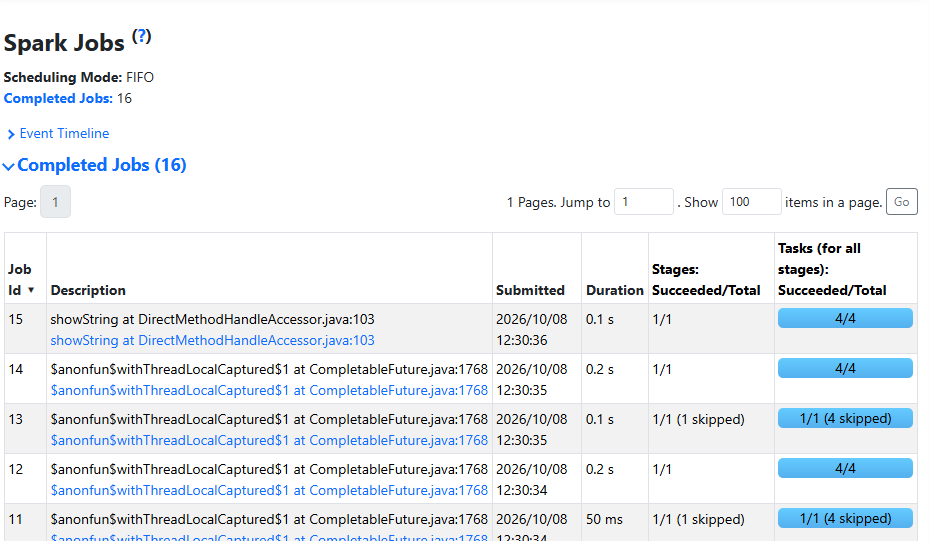